<a href="https://colab.research.google.com/github/mishraaashkacs242511-maker/Machine-Learning-Fundamentals/blob/main/ML_Fundamentals_Prac_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

3. KNN for handwritten digit recognition
Apply KNN on sklearn digits dataset (real-world banking/postal OCR systems).
Visualize nearest neighbors for 3 test images.

Graph 1: Display original MNIST images

Loading MNIST Dataset...
Dataset Shape: (70000, 784)
Total Images: 70000
Total Classes: 10


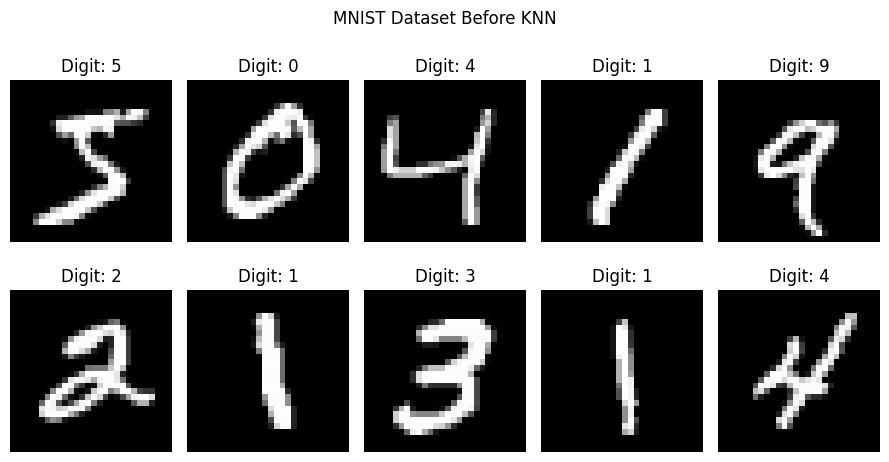

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Loading MNIST Dataset...")

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist.data
y = mnist.target.astype(int)

print("Dataset Shape:", X.shape)
print("Total Images:", len(X))
print("Total Classes:", len(np.unique(y)))

plt.figure(figsize=(9, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title("Digit: " + str(y[i]))
    plt.axis('off')

plt.suptitle("MNIST Dataset Before KNN")
plt.tight_layout()
plt.show()

Graph 2: Display three test images

Training Images: 9600
Testing Images: 2400
Image Size: 28 x 28
Pixel Normalization Completed


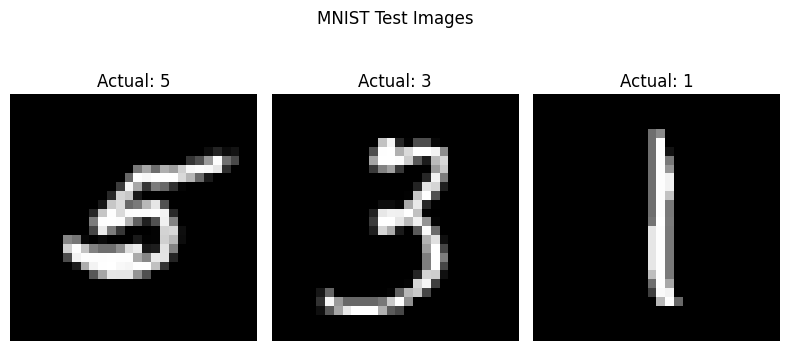

In [2]:
X_sample = X[:12000]
y_sample = y[:12000]

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

X_train = X_train / 255.0
X_test = X_test / 255.0

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

print("Image Size: 28 x 28")
print("Pixel Normalization Completed")

plt.figure(figsize=(8, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Actual: " + str(y_test[i]))
    plt.axis('off')

plt.suptitle("MNIST Test Images")
plt.tight_layout()
plt.show()

Graph 3: Actual vs Predicted digits

Training KNN Model...

KNN Model Accuracy: 95.62 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       241
           1       0.92      1.00      0.96       270
           2       0.98      0.96      0.97       235
           3       0.93      0.93      0.93       246
           4       0.99      0.95      0.97       237
           5       0.96      0.95      0.95       209
           6       0.96      0.98      0.97       242
           7       0.96      0.96      0.96       256
           8       0.97      0.88      0.92       225
           9       0.93      0.96      0.94       239

    accuracy                           0.96      2400
   macro avg       0.96      0.96      0.96      2400
weighted avg       0.96      0.96      0.96      2400



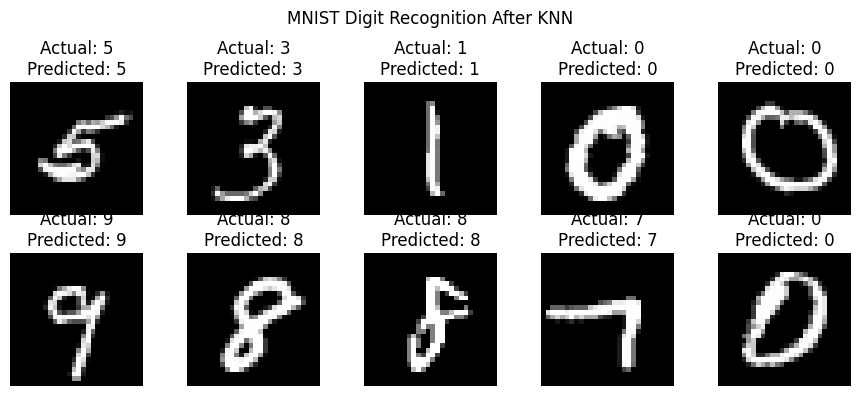

In [3]:
model = KNeighborsClassifier(
    n_neighbors=3,
    metric='euclidean'
)

print("Training KNN Model...")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nKNN Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(9, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(y_pred[i]))
    plt.axis('off')

plt.suptitle("MNIST Digit Recognition After KNN")
plt.tight_layout()
plt.show()

Nearest Neighbors for 3 test images

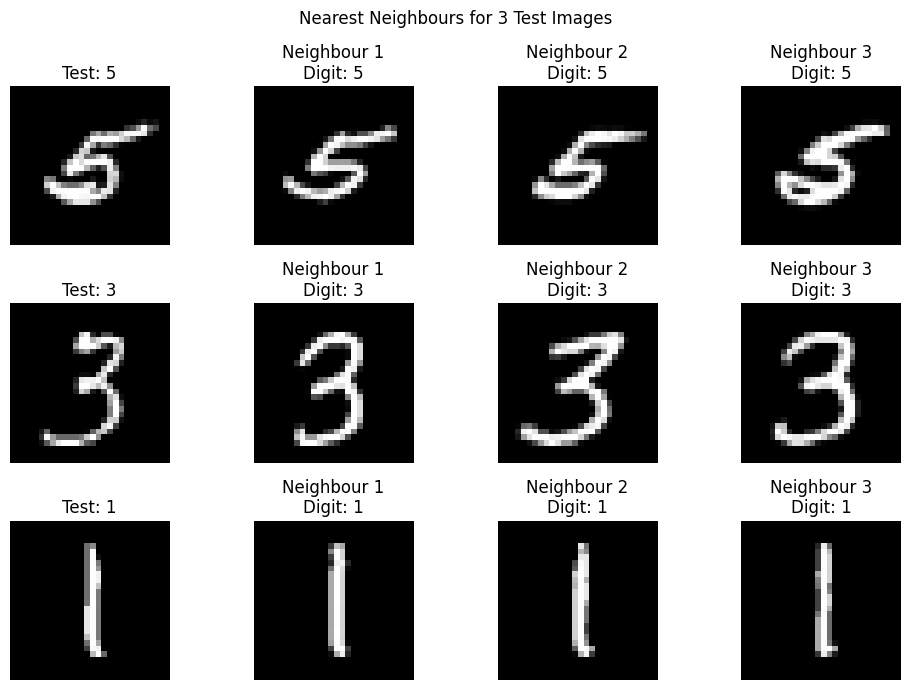

In [4]:
distances, indices = model.kneighbors(X_test[:3])

plt.figure(figsize=(10, 7))

for i in range(3):

    plt.subplot(3, 4, i * 4 + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title("Test: " + str(y_test[i]))
    plt.axis('off')

    for j in range(3):

        plt.subplot(3, 4, i * 4 + j + 2)

        neighbour = X_train[indices[i][j]]

        plt.imshow(neighbour.reshape(28, 28), cmap='gray')

        plt.title(
            "Neighbour " + str(j + 1) +
            "\nDigit: " + str(y_train[indices[i][j]])
        )

        plt.axis('off')

plt.suptitle("Nearest Neighbours for 3 Test Images")
plt.tight_layout()
plt.show()